# Scaling, Bauer's Theorem, Skeel Condition Number & Iterative Refinement
**Computational Linear Algebra (MA30241), IIT Kharagpur, 2026-27**

Priti Kumari (24MA10007) · Ankit Parihar (25MA40004) · Sudev Prasan Patra (25MA40036)

**Goal.** Show that a *badly row-scaled* matrix can have a huge normwise condition number $\kappa(A)$ even though the system is perfectly well-behaved, and that the **Skeel condition number** $\mathrm{cond}(A)=\|\,|A^{-1}||A|\,\|_\infty$ (invariant under row scaling) tells the truth. Then we use iterative refinement to reach componentwise backward stability.

Sections: 0 Setup · 1 Bauer / scaling demo · 2 Skeel invariance · 3 Main example (κ lies, Skeel tells truth) · 4 Iterative refinement · 5 Plots

In [1]:
import numpy as np, scipy.linalg as sla
from fractions import Fraction
import matplotlib.pyplot as plt
np.set_printoptions(linewidth=140, precision=3)
u = np.finfo(np.float64).eps/2          # unit roundoff (double)

inf = np.inf
def kappa_inf(A):            # normwise condition number  ||A||_inf ||A^-1||_inf
    return np.linalg.norm(A,inf)*np.linalg.norm(np.linalg.inv(A),inf)

def skeel_cond(A):           # cond(A) = || |A^-1| |A| ||_inf   (Skeel)
    Ai = np.linalg.inv(A)
    return np.linalg.norm(np.abs(Ai)@np.abs(A), inf)

def skeel_cond_x(A,x):       # cond(A,x) = || |A^-1||A||x| ||_inf / ||x||_inf
    Ai = np.linalg.inv(A)
    return np.linalg.norm(np.abs(Ai)@np.abs(A)@np.abs(x), inf)/np.linalg.norm(x,inf)

def comp_backward_error(A,x,b):   # Oettli-Prager: min w s.t. (A+dA)x=b+db, |dA|<=w|A|, |db|<=w|b|
    r = b - A@x
    d = np.abs(A)@np.abs(x) + np.abs(b)
    return np.max(np.abs(r)/d)

def exact_residual(A,x,b):        # r = b - Ax computed EXACTLY (rational arithmetic), rounded once to double
    n=len(b); r=np.zeros(n)
    for i in range(n):
        s=Fraction(float(b[i]))
        for j in range(n): s-=Fraction(float(A[i,j]))*Fraction(float(x[j]))
        r[i]=float(s)
    return r
print('unit roundoff u =', u)

unit roundoff u = 1.1102230246251565e-16


## 1. Bauer's theorem – rescaling does not change what Gaussian elimination does

**Theorem (Bauer).** If $D_1,D_2$ are diagonal with entries that are powers of the floating-point base $\beta$ (so scaling is exact), then Gaussian elimination applied to $A$ and to $\tilde A=D_1AD_2$ with the *same pivot sequence* performs the same arithmetic: the computed solutions satisfy $\tilde x = D_2^{-1}x$ **bit for bit**. Rescaling alone cannot remove roundoff error; it only changes which pivots are chosen (when pivoting by magnitude).

We verify this numerically with a LU **without pivoting** (pivot order fixed) and with scaling by powers of 2.

In [2]:
def ge_nopivot_solve(A,b):
    A=A.astype(float).copy(); b=b.astype(float).copy(); n=len(b)
    for k in range(n-1):
        for i in range(k+1,n):
            m=A[i,k]/A[k,k]; A[i,k:]-=m*A[k,k:]; b[i]-=m*b[k]
    x=np.zeros(n)
    for i in range(n-1,-1,-1): x[i]=(b[i]-A[i,i+1:]@x[i+1:])/A[i,i]
    return x

rng=np.random.default_rng(1)
n=6
A=rng.standard_normal((n,n))+n*np.eye(n); b=rng.standard_normal(n)
D1=np.diag(2.0**rng.integers(-20,20,n)); D2=np.diag(2.0**rng.integers(-20,20,n))
x  = ge_nopivot_solve(A,b)
xt = ge_nopivot_solve(D1@A@D2, D1@b)          # solves (D1 A D2) y = D1 b, y = D2^-1 x
print('max |D2^-1 x - y| =', np.max(np.abs(np.linalg.inv(D2)@x - xt)), ' (0.0 means bitwise identical)')
print('bitwise identical:', np.array_equal(np.linalg.inv(D2)@x, xt))

max |D2^-1 x - y| = 0.0  (0.0 means bitwise identical)
bitwise identical: True


**Limitation of scaling heuristics.** If the scaling is *not* a power of 2, or if partial pivoting is used, scaling changes the pivot choices, and there is no scaling that is guaranteed to be better. Below, GEPP on the same system with three different row scalings gives different (not uniformly better) accuracy.

In [3]:
def gepp_solve(A,b):
    lu,piv=sla.lu_factor(A); return sla.lu_solve((lu,piv),b)

n=8; rng=np.random.default_rng(7)
B=rng.standard_normal((n,n)); xtrue=np.ones(n)
rows=[]
for name,d in [('none',np.ones(n)),
               ('random 10^[-6,6]',10.0**rng.integers(-6,7,n)),
               ('row-equilibrated (max=1)',1/np.abs(B).max(axis=1))]:
    A=np.diag(d)@B; b=A@xtrue
    x=gepp_solve(A,b)
    rows.append((name,kappa_inf(A),skeel_cond(A),np.linalg.norm(x-xtrue,inf)/np.linalg.norm(xtrue,inf)))
print(f"{'row scaling':28s}{'kappa_inf':>12s}{'Skeel cond':>12s}{'rel. error':>12s}")
for r in rows: print(f"{r[0]:28s}{r[1]:12.2e}{r[2]:12.2e}{r[3]:12.2e}")

row scaling                    kappa_inf  Skeel cond  rel. error
none                            2.17e+01    1.39e+01    8.88e-16
random 10^[-6,6]                2.18e+12    1.39e+01    3.33e-15
row-equilibrated (max=1)        2.05e+01    1.39e+01    5.55e-16


## 2. Skeel condition number is invariant under row scaling

For nonsingular diagonal $D$: $\;(DA)^{-1}\,|DA| \to |A^{-1}D^{-1}|\,|D||A| = |A^{-1}||D^{-1}||D||A| = |A^{-1}||A|$, since $|D^{-1}||D|=I$. Hence $\mathrm{cond}(DA)=\mathrm{cond}(A)$, while $\kappa(DA)$ can be made arbitrarily large.

In [4]:
rng=np.random.default_rng(3)
A=rng.standard_normal((5,5))
print(f"{'D = diag(10^k) , k':>22s}{'kappa_inf(DA)':>16s}{'cond_Skeel(DA)':>18s}")
for k in [0,2,4,6,8]:
    D=np.diag(10.0**(k*np.array([1,-1,0.5,-0.5,0])))
    print(f"{'k = '+str(k):>22s}{kappa_inf(D@A):16.3e}{skeel_cond(D@A):18.6f}")

    D = diag(10^k) , k   kappa_inf(DA)    cond_Skeel(DA)
                 k = 0       1.036e+02         49.612554
                 k = 2       1.501e+05         49.612554
                 k = 4       1.141e+09         49.612554
                 k = 6       1.107e+13         49.612554
                 k = 8       1.103e+17         49.612554


## 3. Main example: normwise κ falsely alarms, Skeel cond tells the truth

Take a well-conditioned $B$ and destroy it by row scaling: $A = D B$, $D=\mathrm{diag}(10^{6},1,10^{-6},10^{3})$.

In [5]:
B=np.array([[4.,1,2,1],[1,5,1,2],[2,1,6,1],[1,2,1,7]])
D=np.diag([1e6,1,1e-6,1e3])
A=D@B
xtrue=np.array([1.,-2,3,-4])
b=A@xtrue

print('kappa_inf(B)      = %.3e   (well conditioned)'%kappa_inf(B))
print('kappa_inf(A=DB)   = %.3e   <-- looks hopeless'%kappa_inf(A))
print('cond_Skeel(B)     = %.3e'%skeel_cond(B))
print('cond_Skeel(A)     = %.3e   <-- identical: invariant under row scaling'%skeel_cond(A))
print('cond_Skeel(A,x)   = %.3e'%skeel_cond_x(A,xtrue))

x=gepp_solve(A,b)
fe=np.linalg.norm(x-xtrue,inf)/np.linalg.norm(xtrue,inf)
print()
print('GEPP relative forward error          = %.3e'%fe)
print('normwise bound   kappa * u           = %.3e   (pessimistic by ~12 orders of magnitude)'%(kappa_inf(A)*u))
print('Skeel bound      cond(A,x) * u       = %.3e   (sharp)'%(skeel_cond_x(A,xtrue)*u))
print('componentwise backward error of x    = %.3e   (~ unit roundoff)'%comp_backward_error(A,x,b))

kappa_inf(B)      = 5.077e+00   (well conditioned)
kappa_inf(A=DB)   = 1.622e+12   <-- looks hopeless
cond_Skeel(B)     = 3.979e+00
cond_Skeel(A)     = 3.979e+00   <-- identical: invariant under row scaling
cond_Skeel(A,x)   = 2.240e+00

GEPP relative forward error          = 7.772e-16
normwise bound   kappa * u           = 1.801e-04   (pessimistic by ~12 orders of magnitude)
Skeel bound      cond(A,x) * u       = 2.486e-16   (sharp)
componentwise backward error of x    = 3.388e-16   (~ unit roundoff)


In [6]:
# The scaling is purely cosmetic: solve the *equilibrated* system and compare
Aeq=np.diag(1/np.abs(A).max(axis=1))@A; beq=np.diag(1/np.abs(A).max(axis=1))@b
print('kappa_inf after row equilibration = %.3e,  Skeel = %.3e'%(kappa_inf(Aeq),skeel_cond(Aeq)))
xe=gepp_solve(Aeq,beq)
print('forward error original: %.2e   equilibrated: %.2e'%(fe,np.linalg.norm(xe-xtrue,inf)/np.linalg.norm(xtrue,inf)))

kappa_inf after row equilibration = 4.266e+00,  Skeel = 3.979e+00
forward error original: 7.77e-16   equilibrated: 2.22e-16


## 4. Iterative refinement ⇒ componentwise backward stability

Algorithm: solve $Ax_0=b$ with LU in **working precision** (here float32 to make the effect visible), then repeat
$r_k=b-Ax_k$ (computed **exactly**, i.e. in higher precision), solve $Ad_k=r_k$ with the same LU, $x_{k+1}=x_k+d_k$.

Theorem (Skeel; Higham): with residuals in extra precision, if $\mathrm{cond}(A)\,u_{work}$ is small enough the iteration converges and the final $x$ has componentwise backward error $\omega\approx u$ (the precision in which $x$ is stored).

In [7]:
def iterative_refinement(A,b,iters=6):
    A32=A.astype(np.float32)
    lu,piv=sla.lu_factor(A32)
    solve32=lambda r: sla.lu_solve((lu,piv),r.astype(np.float32)).astype(np.float64)
    x=solve32(b); hist=[x.copy()]
    for _ in range(iters):
        r=exact_residual(A,x,b)
        x=x+solve32(r); hist.append(x.copy())
    return hist

hist=iterative_refinement(A,b,6)
print(f"{'iter':>4s}{'comp. backward err':>22s}{'rel. forward err':>20s}")
bw=[];fw=[]
for k,xk in enumerate(hist):
    bw.append(comp_backward_error(A,xk,b)); fw.append(np.linalg.norm(xk-xtrue,inf)/np.linalg.norm(xtrue,inf))
    print(f"{k:4d}{bw[-1]:22.3e}{fw[-1]:20.3e}")

iter    comp. backward err    rel. forward err
   0             2.980e-07           5.960e-07
   1             5.510e-14           1.137e-13
   2             0.000e+00           2.776e-17
   3             0.000e+00           2.776e-17
   4             0.000e+00           2.776e-17
   5             0.000e+00           2.776e-17
   6             0.000e+00           2.776e-17


**Contrast.** A matrix that is *genuinely* ill-conditioned (large Skeel cond) – refinement still helps backward error but the forward error is limited by $\mathrm{cond}(A,x)\,u$.

In [8]:
H=sla.hilbert(8); xh=np.ones(8); bh=H@xh
print('Hilbert(8): kappa_inf = %.2e, Skeel cond = %.2e  (both large -> truly ill conditioned)'%(kappa_inf(H),skeel_cond(H)))
xg=gepp_solve(H,bh)
print('GEPP forward error = %.2e  vs  cond*u = %.2e'%(np.linalg.norm(xg-xh,inf),skeel_cond(H)*u))

Hilbert(8): kappa_inf = 3.39e+10, Skeel cond = 1.16e+10  (both large -> truly ill conditioned)
GEPP forward error = 4.84e-07  vs  cond*u = 1.28e-06


## 5. Plots

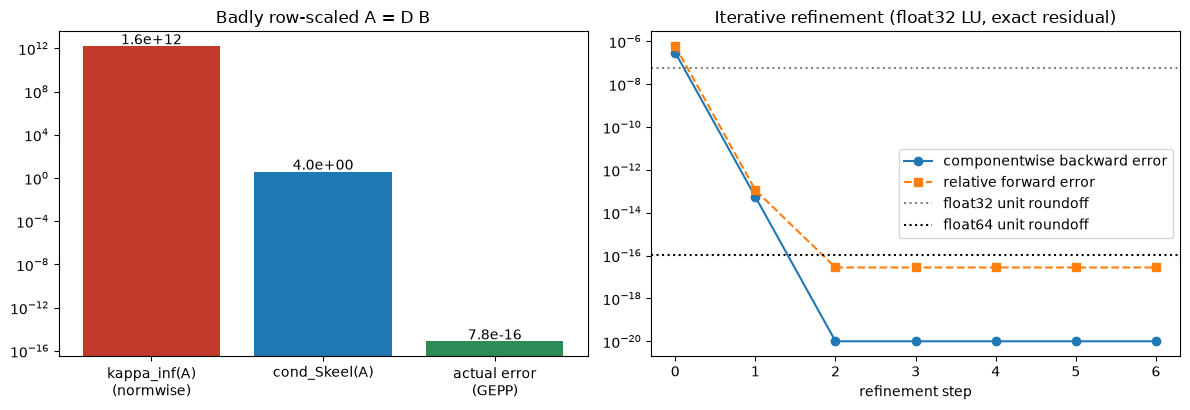

In [9]:
fig,ax=plt.subplots(1,2,figsize=(12,4.2))
names=['kappa_inf(A)\n(normwise)','cond_Skeel(A)','actual error\n(GEPP)']
vals=[kappa_inf(A),skeel_cond(A),max(fe,1e-17)]
ax[0].bar(names,vals,color=['#c0392b','#1f77b4','#2e8b57']); ax[0].set_yscale('log')
ax[0].set_title('Badly row-scaled A = D B'); 
for i,v in enumerate(vals): ax[0].text(i,v*1.5,'%.1e'%v,ha='center')
ax[1].semilogy(range(len(bw)),np.maximum(bw,1e-20),'o-',label='componentwise backward error')
ax[1].semilogy(range(len(fw)),np.maximum(fw,1e-20),'s--',label='relative forward error')
ax[1].axhline(2**-24,color='gray',ls=':',label='float32 unit roundoff'); ax[1].axhline(u,color='k',ls=':',label='float64 unit roundoff')
ax[1].set_xlabel('refinement step'); ax[1].legend(); ax[1].set_title('Iterative refinement (float32 LU, exact residual)')
plt.tight_layout(); plt.savefig('results.png',dpi=150); plt.show()